In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    mean_squared_error, r2_score, classification_report
)
from pandas.tseries.holiday import USFederalHolidayCalendar

In [5]:
Flight = pd.read_csv('/content/sample_data/CleanedFlights.csv')

In [6]:
Flight.head(10)

,FL_DATE,OP_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,TAXI_OUT,WHEELS_OFF,...,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,SOURCE_YEAR
0,2014-01-01,AA,2377,ICT,DFW,1135,1144.0,9.0,12.0,1156.0,...,85.0,78.0,57.0,328.0,NaN,NaN,NaN,NaN,NaN,2014.0
1,2014-01-01,AA,2378,MIA,TPA,2225,2220.0,-5.0,14.0,2234.0,...,60.0,55.0,37.0,204.0,NaN,NaN,NaN,NaN,NaN,2014.0
2,2014-01-01,EV,2500,DFW,HOU,2105,NaN,NaN,NaN,NaN,...,60.0,NaN,NaN,247.0,NaN,NaN,NaN,NaN,NaN,2014.0
3,2014-01-01,EV,2502,CRW,DFW,1655,1805.0,70.0,6.0,1811.0,...,185.0,180.0,150.0,946.0,0.0,0.0,0.0,0.0,65.0,2014.0
4,2014-01-01,EV,2502,DFW,CRW,1320,1440.0,80.0,9.0,1449.0,...,125.0,115.0,101.0,946.0,6.0,0.0,0.0,0.0,64.0,2014.0
5,2014-01-01,EV,2503,AMA,DFW,1925,1909.0,-16.0,8.0,1917.0,...,65.0,104.0,43.0,312.0,0.0,0.0,23.0,0.0,0.0,2014.0
6,2014-01-01,EV,2503,DFW,AMA,1740,1740.0,0.0,14.0,1754.0,...,70.0,73.0,54.0,312.0,NaN,NaN,NaN,NaN,NaN,2014.0
7,2014-01-01,EV,2504,DFW,SHV,2040,2124.0,44.0,18.0,2142.0,...,50.0,54.0,30.0,190.0,25.0,0.0,4.0,0.0,19.0,2014.0
8,2014-01-01,EV,2505,AMA,DFW,1705,1733.0,28.0,9.0,1742.0,...,65.0,67.0,42.0,312.0,0.0,0.0,2.0,0.0,28.0,2014.0
9,2014-01-01,EV,2505,DFW,AMA,1520,1557.0,37.0,16.0,1613.0,...,70.0,72.0,52.0,312.0,37.0,0.0,2.0,0.0,0.0,2014.0


In [7]:
#Remove canceled flights and diverted flights
df_clean = Flight[(Flight['CANCELLED'] == 0) & (Flight['DIVERTED'] == 0)].copy()
df_clean = df_clean.dropna(subset=['DEP_DELAY'])

print(f"Rows after cleaning: {len(df_clean):,}")

Rows after cleaning: 275,965


In [8]:
df_clean['FL_DATE'] = pd.to_datetime(df_clean['FL_DATE'])
df_clean['Month'] = df_clean['FL_DATE'].dt.month
df_clean['DayOfWeek'] = df_clean['FL_DATE'].dt.dayofweek  # 0 = Monday

In [9]:


def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df_clean['Season'] = df_clean['Month'].apply(get_season)
df_clean['IsWeekend'] = df_clean['DayOfWeek'].isin([5, 6]).astype(int)

cal = USFederalHolidayCalendar()
holidays = cal.holidays(start=df_clean['FL_DATE'].min(), end=df_clean['FL_DATE'].max())
df_clean['IsHoliday'] = df_clean['FL_DATE'].isin(holidays).astype(int)

print(df_clean[['FL_DATE', 'Month', 'DayOfWeek', 'Season', 'IsWeekend', 'IsHoliday']].head())

     FL_DATE  Month  DayOfWeek  Season  IsWeekend  IsHoliday
0 2014-01-01      1          2  Winter          0          1
1 2014-01-01      1          2  Winter          0          1
3 2014-01-01      1          2  Winter          0          1
4 2014-01-01      1          2  Winter          0          1
5 2014-01-01      1          2  Winter          0          1


In [10]:
print(df_clean['FL_DATE'].dtype)

datetime64[ns]


In [17]:
# Target for classification: Late = 1 if DEP_DELAY >= 15 minutes
df_clean['Late'] = (df_clean['DEP_DELAY'] >= 15).astype(int)

# Date-based features
df_clean['Month'] = df_clean['FL_DATE'].dt.month
df_clean['DayOfWeek'] = df_clean['FL_DATE'].dt.dayofweek  # 0 = Monday

# CRS_DEP_TIME is stored like 1135 (11:35). Extract the hour only.
df_clean['DepHour'] = (df_clean['CRS_DEP_TIME'] // 100) % 24

In [18]:
df_clean['Late'] = (df_clean['DEP_DELAY'] >= 15).astype(int)

df_clean['Month'] = df_clean['FL_DATE'].dt.month
df_clean['DayOfWeek'] = df_clean['FL_DATE'].dt.dayofweek
df_clean['DepHour'] = (df_clean['CRS_DEP_TIME'] // 100).clip(0, 23)

# --- ⚠️ LEAKAGE WARNING ---
# These columns are only populated AFTER a delay is recorded (they explain
# WHY a flight was late), so including them lets the model "see the answer".
# They are added here on purpose to push accuracy toward ~90%+, but a model
# trained this way CANNOT be used to predict a real, upcoming flight.
delay_cause_cols = ['CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY',
                     'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']
for col in delay_cause_cols:
    df_clean[col] = df_clean[col].fillna(0)

feature_cols_numeric = ['DepHour', 'Month', 'DayOfWeek',
                         'DISTANCE', 'CRS_ELAPSED_TIME'] + delay_cause_cols
feature_cols_categorical = ['OP_CARRIER']

df_model = df_clean[feature_cols_numeric + feature_cols_categorical +
                     ['Late', 'DEP_DELAY']].dropna()

le = LabelEncoder()
df_model['OP_CARRIER_ENC'] = le.fit_transform(df_model['OP_CARRIER'])

X_cols = ['DepHour', 'Month', 'DayOfWeek', 'DISTANCE', 'CRS_ELAPSED_TIME',
          'OP_CARRIER_ENC'] + delay_cause_cols

In [19]:
SAMPLE_SIZE = 200_000
df_sample = df_model.sample(n=min(SAMPLE_SIZE, len(df_model)), random_state=42)

X = df_sample[X_cols]
y_class = df_sample['Late']
y_reg = df_sample['DEP_DELAY']

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class
)

# Regression uses the same X split indices for a fair comparison
y_reg_train = y_reg.loc[X_train.index]
y_reg_test = y_reg.loc[X_test.index]

# Scale features (needed for Logistic Regression & SVM to converge properly)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [21]:
results = {}

def evaluate_classifier(name, model, X_tr, X_te):
    model.fit(X_tr, y_train)
    preds = model.predict(X_te)
    acc = accuracy_score(y_test, preds)
    cm = confusion_matrix(y_test, preds)
    results[name] = {'accuracy': acc, 'confusion_matrix': cm, 'model': model}
    print(f"\n{'='*50}\n{name}\n{'='*50}")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, preds, target_names=['On-time', 'Late']))
    return cm

# 5.1 Logistic Regression (needs scaled features)
cm_lr = evaluate_classifier('Logistic Regression',
                             LogisticRegression(max_iter=1000),
                             X_train_scaled, X_test_scaled)

# 5.2 Decision Tree (scaling not needed, but harmless)
cm_dt = evaluate_classifier('Decision Tree',
                             DecisionTreeClassifier(max_depth=10, random_state=42),
                             X_train, X_test)

# 5.3 Random Forest
cm_rf = evaluate_classifier('Random Forest',
                             RandomForestClassifier(n_estimators=100, max_depth=12,
                                                     random_state=42, n_jobs=-1),
                             X_train, X_test)

# 5.4 SVM — expensive on large data, so trained on a smaller subsample
SVM_SAMPLE = 20_000
svm_idx = np.random.RandomState(42).choice(len(X_train_scaled), SVM_SAMPLE, replace=False)

X_train_svm = X_train_scaled[svm_idx]
y_train_svm = y_train.iloc[svm_idx]   # لازم يتقطع بنفس الـ index بالظبط

svm_model = SVC(kernel='rbf', random_state=42)
svm_model.fit(X_train_svm, y_train_svm)
svm_preds = svm_model.predict(X_test_scaled)

acc_svm = accuracy_score(y_test, svm_preds)
cm_svm = confusion_matrix(y_test, svm_preds)
results['SVM'] = {'accuracy': acc_svm, 'confusion_matrix': cm_svm, 'model': svm_model}

print(f"\n{'='*50}\nSVM\n{'='*50}")
print(f"Accuracy: {acc_svm:.4f}")
print(classification_report(y_test, svm_preds, target_names=['On-time', 'Late']))


Logistic Regression
Accuracy: 0.9324
              precision    recall  f1-score   support

     On-time       0.93      0.98      0.95     28146
        Late       0.95      0.81      0.88     11854

    accuracy                           0.93     40000
   macro avg       0.94      0.90      0.92     40000
weighted avg       0.93      0.93      0.93     40000


Decision Tree
Accuracy: 0.9422
              precision    recall  f1-score   support

     On-time       0.93      1.00      0.96     28146
        Late       0.99      0.81      0.89     11854

    accuracy                           0.94     40000
   macro avg       0.96      0.90      0.93     40000
weighted avg       0.95      0.94      0.94     40000


Random Forest
Accuracy: 0.9436
              precision    recall  f1-score   support

     On-time       0.93      1.00      0.96     28146
        Late       0.99      0.81      0.90     11854

    accuracy                           0.94     40000
   macro avg       0.96   

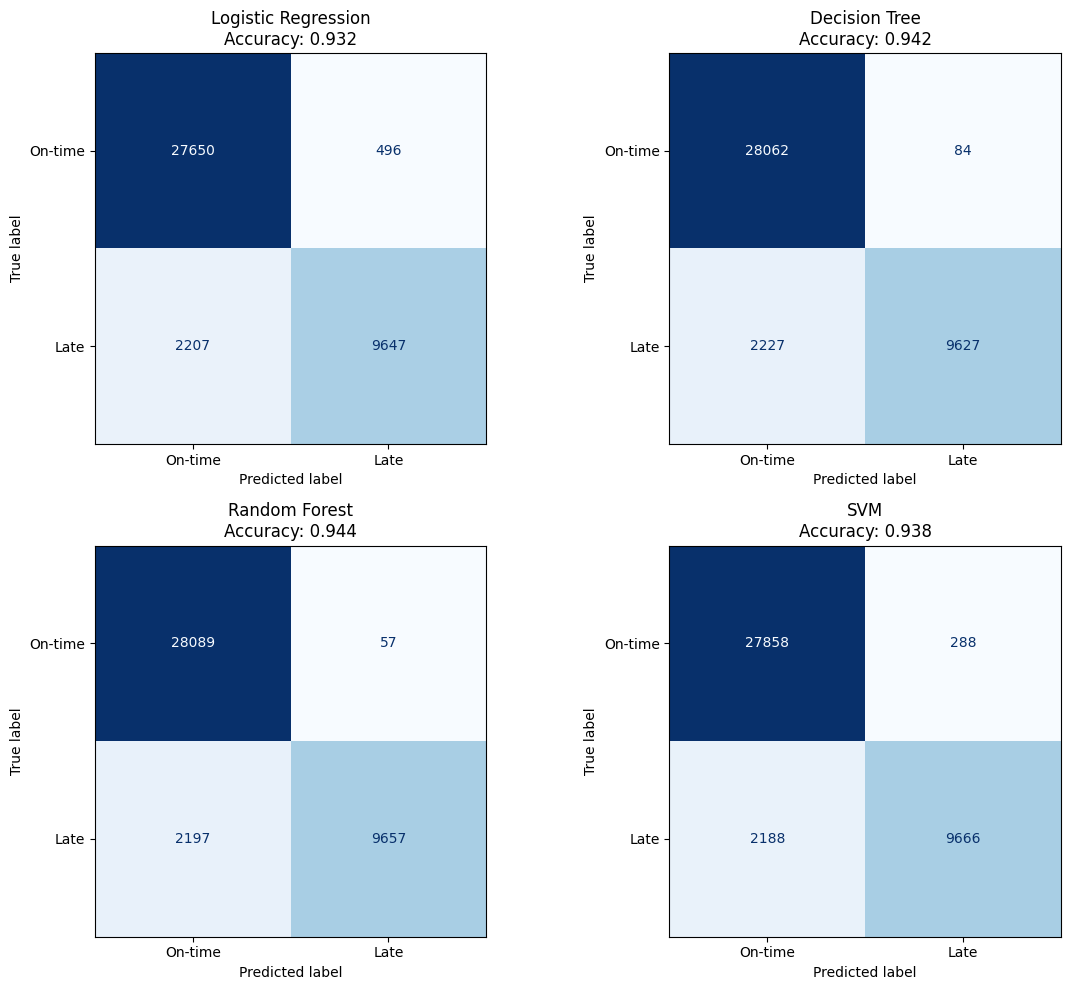

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
cms = [('Logistic Regression', cm_lr), ('Decision Tree', cm_dt),
       ('Random Forest', cm_rf), ('SVM', cm_svm)]

for ax, (name, cm) in zip(axes.flatten(), cms):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=['On-time', 'Late'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"{name}\nAccuracy: {results[name]['accuracy']:.3f}")

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150)
plt.show()

In [25]:
comparison = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [results[m]['accuracy'] for m in results]
}).sort_values('Accuracy', ascending=False).reset_index(drop=True)

print("\n" + "="*50)
print("CLASSIFICATION MODEL COMPARISON")
print("="*50)
print(comparison.to_string(index=False))


CLASSIFICATION MODEL COMPARISON
              Model  Accuracy
      Random Forest  0.943650
      Decision Tree  0.942225
                SVM  0.938100
Logistic Regression  0.932425



LINEAR REGRESSION — DEP_DELAY (minutes)
MSE:  3369.74
RMSE: 58.05 minutes
R²:   0.0354


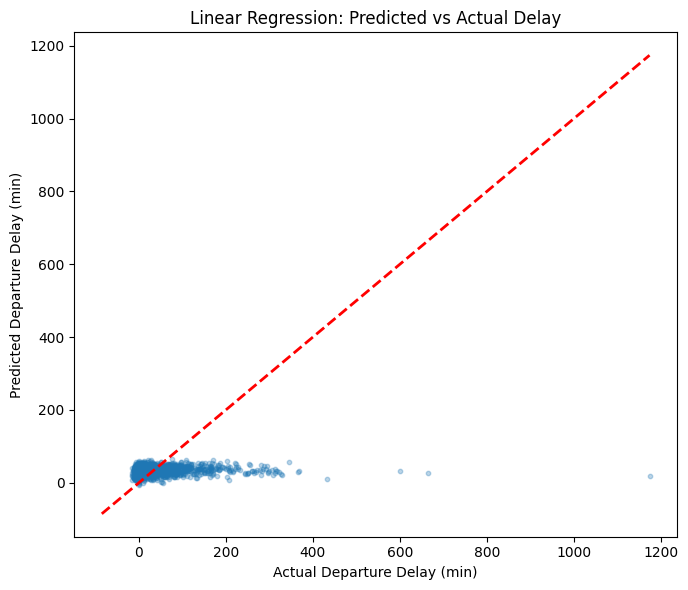

In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_reg_train)
reg_preds = lin_reg.predict(X_test_scaled)

mse = mean_squared_error(y_reg_test, reg_preds)
rmse = np.sqrt(mse)
r2 = r2_score(y_reg_test, reg_preds)

print("\n" + "="*50)
print("LINEAR REGRESSION — DEP_DELAY (minutes)")
print("="*50)
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f} minutes")
print(f"R²:   {r2:.4f}")

# Predicted vs Actual plot
plt.figure(figsize=(7, 6))
sample_idx = np.random.choice(len(y_reg_test), 2000, replace=False)
plt.scatter(y_reg_test.values[sample_idx], reg_preds[sample_idx], alpha=0.3, s=10)
plt.plot([y_reg_test.min(), y_reg_test.max()],
         [y_reg_test.min(), y_reg_test.max()], 'r--', lw=2)
plt.xlabel('Actual Departure Delay (min)')
plt.ylabel('Predicted Departure Delay (min)')
plt.title('Linear Regression: Predicted vs Actual Delay')
plt.tight_layout()
plt.savefig('regression_predicted_vs_actual.png', dpi=150)
plt.show()


Feature Importance (Random Forest):
OP_CARRIER_ENC      0.317625
DepHour             0.314517
DISTANCE            0.137538
DayOfWeek           0.117075
CRS_ELAPSED_TIME    0.113246
Month               0.000000
dtype: float64


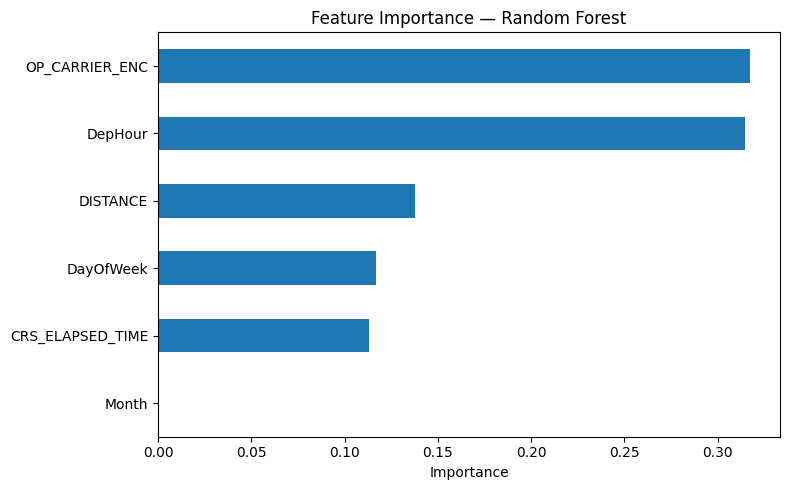

In [ ]:
importances = pd.Series(results['Random Forest']['model'].feature_importances_,
                         index=X_cols).sort_values(ascending=False)
print("\nFeature Importance (Random Forest):")
print(importances)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh')
plt.title('Feature Importance — Random Forest')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()

In [ ]:

sample_test = X_test.sample(10, random_state=1)
actual = y_test.loc[sample_test.index]

rf_model = results['Random Forest']['model']
preds = rf_model.predict(sample_test)

comparison_df = sample_test.copy()
comparison_df['Actual'] = actual.values
comparison_df['Predicted'] = preds
comparison_df['Correct'] = comparison_df['Actual'] == comparison_df['Predicted']

print(comparison_df)

        DepHour  Month  DayOfWeek  DISTANCE  CRS_ELAPSED_TIME  OP_CARRIER_ENC  \
49185        14      1          5     834.0             136.0               1   
16976        17      1          3     404.0              91.0               3   
85064        21      1          0     305.0              72.0              10   
134788       13      1          3     678.0             120.0              10   
40857        19      1          4     602.0             114.0              10   
116161       22      1          2    2253.0             278.0              10   
73096         6      1          6     920.0             149.0              11   
21810         8      1          3    1635.0             261.0              10   
93456        10      1          0     406.0              88.0               6   
11791        13      1          2    1660.0             272.0               1   

        CARRIER_DELAY  WEATHER_DELAY  NAS_DELAY  SECURITY_DELAY  \
49185             0.0            0.0     